# Task 2: Ensemble Learning and Tree-Based Models (Titanic)


In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance
import xgboost as xgb
from xgboost import XGBClassifier

# Visualization and reproducibility settings
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 10
RANDOM_STATE = 42

DATA_PATH = r"C:\Users\rithy\OneDrive\Desktop\marvel_level3\task2\Titanic-Dataset.csv" 


### Step 1: Exploratory Data Analysis
In this step we:
- Load the dataset and check its shape
- Look at sample rows to understand the data
- Check column names, data types, and non-null counts
- Identify which columns have missing values
- Look at how survival is distributed across gender and ticket class

**Features in the dataset:**
| Feature | What it is |
|---|---|
| `PassengerId` | Unique ID for each passenger, not useful for prediction |
| `Survived` | Whether the passenger survived (1) or not (0), this is our target |
| `Pclass` | Ticket class: 1st, 2nd, or 3rd class |
| `Name` | Full name, contains titles like Mr, Mrs, Miss which we will extract later |
| `Sex` | Passenger gender |
| `Age` | Passenger age, has some missing values |
| `SibSp` | Number of siblings or spouses on board |
| `Parch` | Number of parents or children on board |
| `Ticket` | Ticket number, mostly noise |
| `Fare` | Price paid for the ticket |
| `Cabin` | Cabin number, mostly missing |
| `Embarked` | Port where the passenger boarded: S, C, or Q |

The countplots show how survival differs across gender and ticket class.

Dataset Shape: 891 rows, 12 columns


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing Value Summary:


,Missing Count
Age,177
Cabin,687
Embarked,2



Overall Survival Rate: 38.38%


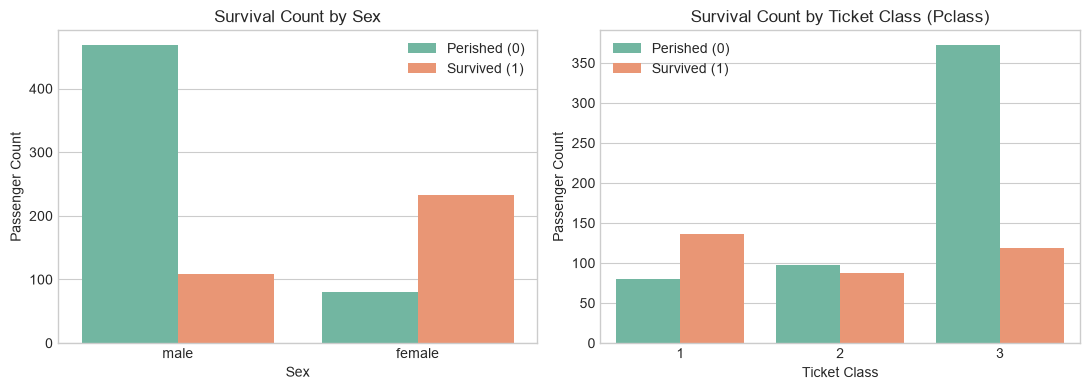

In [5]:
#  Load data
df_raw = pd.read_csv(DATA_PATH)
print(f"Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")

# sample records 
display(df_raw.head())

# All features
df_raw.info()

# Missing values 
missing_summary = pd.DataFrame({
    "Missing Count": df_raw.isna().sum()})
print("\nMissing Value Summary:")
display(missing_summary[missing_summary["Missing Count"] > 0])

# Overall survival rate
overall_survival = df_raw["Survived"].mean()
print(f"\nOverall Survival Rate: {overall_survival:.2%}")

# EDA countplots
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df_raw, x="Sex", hue="Survived", palette="Set2", ax=axes[0])
axes[0].set_title("Survival Count by Sex")
axes[0].set_xlabel("Sex")
axes[0].set_ylabel("Passenger Count")
axes[0].legend(["Perished (0)", "Survived (1)"])
sns.countplot(data=df_raw, x="Pclass", hue="Survived", palette="Set2", ax=axes[1])
axes[1].set_title("Survival Count by Ticket Class (Pclass)")
axes[1].set_xlabel("Ticket Class")
axes[1].set_ylabel("Passenger Count")
axes[1].legend(["Perished (0)", "Survived (1)"])
plt.tight_layout()
plt.show()

### Step 2: Feature Engineering
In this step we drop redundant columns and engineer new features from the existing ones.

**New features created:**
- `FamilySize` = `SibSp + Parch + 1`: total number of people traveling together including the passenger. Solo travelers and very large families had lower survival rates than small groups.
- `IsAlone` = 1 if `FamilySize == 1`, else 0: a direct binary signal for passengers traveling alone.
- `Title`: extracted from `Name` using regex. French variants (`Mlle`, `Ms`) are mapped to `Miss` and `Mme` to `Mrs`. Titles with fewer than 10 occurrences are grouped as `Rare`. This captures gender, age group, and social class.
- `HasCabin` = 1 if a cabin number was recorded, else 0. The cabin column itself is 77% missing, but having a recorded cabin is a strong indicator of wealth and a higher deck location.


**Columns dropped:**
- `PassengerId`: arbitrary row index
- `Name`: title has been extracted, the rest is not useful
- `Ticket`: alphanumeric code with no clear predictive pattern
- `Cabin`: replaced by `HasCabin`

In [6]:
df = df_raw.copy()

# Family features
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

# Title extraction from Name
df["Title"] = df["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)

# Standardize minor variants
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})

# Consolidate rare titles (< 10 occurrences)
title_counts = df["Title"].value_counts()
rare_titles = title_counts[title_counts < 10].index
df["Title"] = df["Title"].apply(lambda t: "Rare" if t in rare_titles else t)

# Cabin indicator
df["HasCabin"] = df["Cabin"].notna().astype(int)

# Drop redundant columns
cols_to_drop = ["PassengerId", "Name", "Ticket", "Cabin"]
df = df.drop(columns=cols_to_drop)

print("dataset after feature engineering preview:")
display(df.head(5))

print(f"Remaining columns ({len(df.columns)}): {list(df.columns)}")

dataset after feature engineering preview:


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone,Title,HasCabin
0,0,3,male,22.0,1,0,7.2500,S,2,0,Mr,0
1,1,1,female,38.0,1,0,71.2833,C,2,0,Mrs,1
2,1,3,female,26.0,0,0,7.9250,S,1,1,Miss,0
3,1,1,female,35.0,1,0,53.1000,S,2,0,Mrs,1
4,0,3,male,35.0,0,0,8.0500,S,1,1,Mr,0


Remaining columns (12): ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize', 'IsAlone', 'Title', 'HasCabin']


### Step 3: Train-Test Split (Leakage Prevention)
We separate features ($X$) and target ($y$), then split the dataset using an 80/20 stratified partition:
- **Why split before imputation?** Calculating summary metrics (such as median age or mode port) across the whole dataset before splitting leaks test set information into the training pipeline (*data leakage*), leading to overly optimistic evaluation metrics.
- **Stratification:** We use `stratify=y` to ensure both the training set and testing set have the exact same ratio of survivors ($y=1$) to non-survivors ($y=0$).
**What to look for:** Verify that the survival percentage matches across both splits and that no rows were dropped during partitioning.

In [7]:
#  Separate features and target
X = df.drop(columns=["Survived"])
y = df["Survived"]

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# Verify shapes and class distributions
split_stats = pd.DataFrame({
    "Split": ["Full Dataset", "Train Set (80%)", "Test Set (20%)"],
    "Samples": [len(df), len(X_train), len(X_test)],
    "Survived Count (1)": [y.sum(), y_train.sum(), y_test.sum()],
    "Survival Rate (%)": [
        round(y.mean() * 100, 2),
        round(y_train.mean() * 100, 2),
        round(y_test.mean() * 100, 2)
    ]
})

display(split_stats)

,Split,Samples,Survived Count (1),Survival Rate (%)
0,Full Dataset,891,342,38.38
1,Train Set (80%),712,273,38.34
2,Test Set (20%),179,69,38.55


### Step 4: Preprocessing via ColumnTransformer
We construct a scikit-learn `ColumnTransformer` to handle imputation and encoding strictly inside the training pipeline:
- **Numeric Features (`Age`, `Fare`, `SibSp`, `Parch`, `FamilySize`, `Pclass`, `IsAlone`, `HasCabin`)**:
  - Imputed using median values (`SimpleImputer(strategy='median')`).
  - **No Feature Scaling**: Decision tree algorithms make orthogonal splits based on relative ordering ($X_j \le \text{threshold}$) rather than distance metrics. Because tree splits are completely invariant to monotonic feature scaling, standardization or MinMax scaling is unnecessary.
- **Categorical Features (`Sex`, `Embarked`, `Title`)**:
  - Imputed using the most frequent category (`SimpleImputer(strategy='most_frequent')`).
  - Encoded using `OneHotEncoder(handle_unknown='ignore', sparse_output=False)` to prevent creating artificial ordinal relationships between unordered categories.
**What to look for:** The transformer will be fitted only on `X_train`. We inspect the transformed training array and verify the generated column names.

In [8]:
# Define column groupings
numeric_cols = ["Age", "Fare", "SibSp", "Parch", "FamilySize", "Pclass", "IsAlone", "HasCabin"]
categorical_cols = ["Sex", "Embarked", "Title"]

# Numeric pipeline: median imputation only, no scaling needed for trees
num_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical pipeline: mode imputation + one-hot encoding
cat_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Combine into ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, numeric_cols),
        ("cat", cat_pipeline, categorical_cols)
    ],
    remainder="drop"
)

# Fit and transform on X_train only to preview the processed feature matrix
preprocessor.fit(X_train)
feature_names = preprocessor.get_feature_names_out()
X_train_transformed_df = pd.DataFrame(
    preprocessor.transform(X_train),
    columns=feature_names,
    index=X_train.index
)
print(f"Transformed Training Shape: {X_train_transformed_df.shape}")
print(f"Generated {len(feature_names)} features after One-Hot Encoding.")
print("\nTransformed Training Set Sample (first 3 rows):")
display(X_train_transformed_df.head(3))

Transformed Training Shape: (712, 18)
Generated 18 features after One-Hot Encoding.

Transformed Training Set Sample (first 3 rows):


,num__Age,num__Fare,num__SibSp,num__Parch,num__FamilySize,num__Pclass,num__IsAlone,num__HasCabin,cat__Sex_female,cat__Sex_male,cat__Embarked_C,cat__Embarked_Q,cat__Embarked_S,cat__Title_Master,cat__Title_Miss,cat__Title_Mr,cat__Title_Mrs,cat__Title_Rare
692,28.5,56.4958,0.0,0.0,1.0,3.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
481,28.5,0.0000,0.0,0.0,1.0,2.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
527,28.5,221.7792,0.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


### Step 5: Model Training
We train three tree-based ensemble models, each representing a different strategy for combining decision trees.
- **Random Forest**: builds many deep, independent trees in parallel on random subsets of the data and features, then averages their predictions. This reduces variance without increasing bias.
- **Gradient Boosting (GBM)**: builds shallow trees sequentially, where each tree corrects the errors of the previous one. This reduces bias but can be slower and more prone to overfitting than Random Forest.
- **XGBoost**: an optimized implementation of gradient boosting with built-in regularization and speed improvements. Often performs better than standard GBM out of the box.
All three models are trained as untuned baselines with `n_estimators=200` and `random_state=42`. Hyperparameter tuning is intentionally deferred to a later task so we can compare the default behavior of each approach.

Each model is wrapped in a `Pipeline` with the preprocessor so the full workflow (imputation, encoding, training) stays in one object.

In [9]:
from time import perf_counter

# Define the three models with fixed n_estimators and random_state for fair comparison
models = {
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=200, random_state=RANDOM_STATE, eval_metric="logloss")
}
pipelines = {}
fit_times = {}
for name, model in models.items():
    # Each pipeline chains the preprocessor and the model into one object
    # This ensures preprocessing is always fitted on training data only
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
    
    start = perf_counter()
    pipe.fit(X_train, y_train)
    fit_times[name] = round(perf_counter() - start, 2)
    
    pipelines[name] = pipe
    print(f"{name} trained in {fit_times[name]}s")

Random Forest trained in 0.45s
Gradient Boosting trained in 0.35s
XGBoost trained in 0.36s


### Step 6: Evaluation Metrics

We evaluate each model on both the training set and the held-out test set.

- **Accuracy**: percentage of correct predictions overall.
- **Precision**: of all passengers predicted as survived, how many actually did.
- **Recall**: of all passengers who actually survived, how many did we correctly identify.
- **F1 Score**: harmonic mean of precision and recall, useful when the classes are not perfectly balanced.

The **train-test accuracy gap** tells us about overfitting. A large gap means the model learned the training data too closely and generalises poorly. We sort by F1 as the primary ranking metric.

In [10]:
results = []

for name, pipe in pipelines.items():
    # Predict on both sets to compare training vs test performance
    train_preds = pipe.predict(X_train)
    test_preds = pipe.predict(X_test)

    results.append({
        "Model": name,
        "Train Accuracy": round(accuracy_score(y_train, train_preds), 4),
        "Test Accuracy": round(accuracy_score(y_test, test_preds), 4),
        # Precision: of predicted survivors, how many actually survived
        "Precision": round(precision_score(y_test, test_preds), 4),
        # Recall: of actual survivors, how many did we catch
        "Recall": round(recall_score(y_test, test_preds), 4),
        # F1: balances precision and recall into one score
        "F1 Score": round(f1_score(y_test, test_preds), 4),
        # A large gap here suggests the model overfit to the training data
        "Train-Test Gap": round(accuracy_score(y_train, train_preds) - accuracy_score(y_test, test_preds), 4),
        "Fit Time (s)": fit_times[name]
    })

# Sort by F1 as the primary ranking metric
results_df = pd.DataFrame(results).sort_values("F1 Score", ascending=False).reset_index(drop=True)
display(results_df)

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,Train-Test Gap,Fit Time (s)
0,XGBoost,0.9860,0.8212,0.7681,0.7681,0.7681,0.1647,0.36
1,Random Forest,0.9874,0.8101,0.7536,0.7536,0.7536,0.1773,0.45
2,Gradient Boosting,0.9396,0.8045,0.7833,0.6812,0.7287,0.1351,0.35


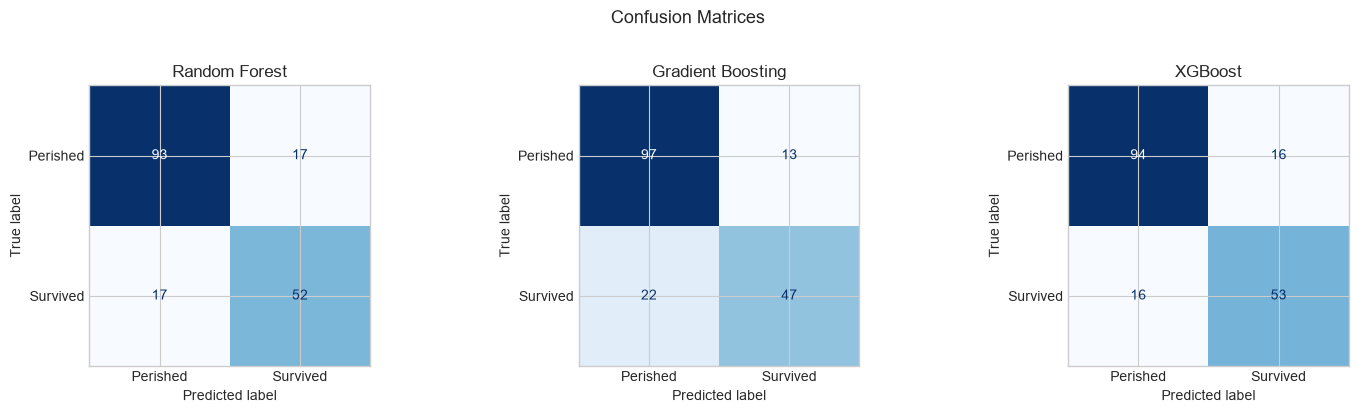


--- Random Forest ---
              precision    recall  f1-score   support

    Perished       0.85      0.85      0.85       110
    Survived       0.75      0.75      0.75        69

    accuracy                           0.81       179
   macro avg       0.80      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179


--- Gradient Boosting ---
              precision    recall  f1-score   support

    Perished       0.82      0.88      0.85       110
    Survived       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179


--- XGBoost ---
              precision    recall  f1-score   support

    Perished       0.85      0.85      0.85       110
    Survived       0.77      0.77      0.77        69

    accuracy                           0.82       179
   macro avg       0.81      0.81      0.81       179
weighte

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, pipe) in zip(axes, pipelines.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    # Rows = actual class, Columns = predicted class
    # Top-left: correctly predicted Perished, Bottom-right: correctly predicted Survived
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Perished", "Survived"]).plot(
        ax=ax, colorbar=False, cmap="Blues"
    )
    ax.set_title(name)

plt.suptitle("Confusion Matrices", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# Detailed breakdown of precision, recall and F1 per class
for name, pipe in pipelines.items():
    print(f"\n--- {name} ---")
    print(classification_report(y_test, pipe.predict(X_test), target_names=["Perished", "Survived"]))

### Step 7: Cross-Validation Stability Check
The test set contains roughly 179 rows, which means a single train-test split can produce noisy metric estimates. A difference of one or two predictions can shift accuracy by nearly 1%.
To get a more reliable picture of model performance, we run **Repeated Stratified K-Fold cross-validation** (5 folds, 3 repeats) on the training set only. This gives us 15 accuracy and F1 scores per model, from which we compute the mean and standard deviation. A high standard deviation indicates the model is sensitive to how the data is split.

,Accuracy Mean,Accuracy Std,F1 Mean,F1 Std
Random Forest,0.8179,0.0297,0.7600,0.0394
Gradient Boosting,0.8216,0.0261,0.7573,0.0384
XGBoost,0.8001,0.0338,0.7357,0.0440


C:\Users\rithy\AppData\Local\Temp\ipykernel_31788\3619869041.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=cv_plot_df, x="Model", y="Accuracy", palette="Set2", ax=axes[0])
C:\Users\rithy\AppData\Local\Temp\ipykernel_31788\3619869041.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=cv_plot_df, x="Model", y="F1", palette="Set2", ax=axes[1])


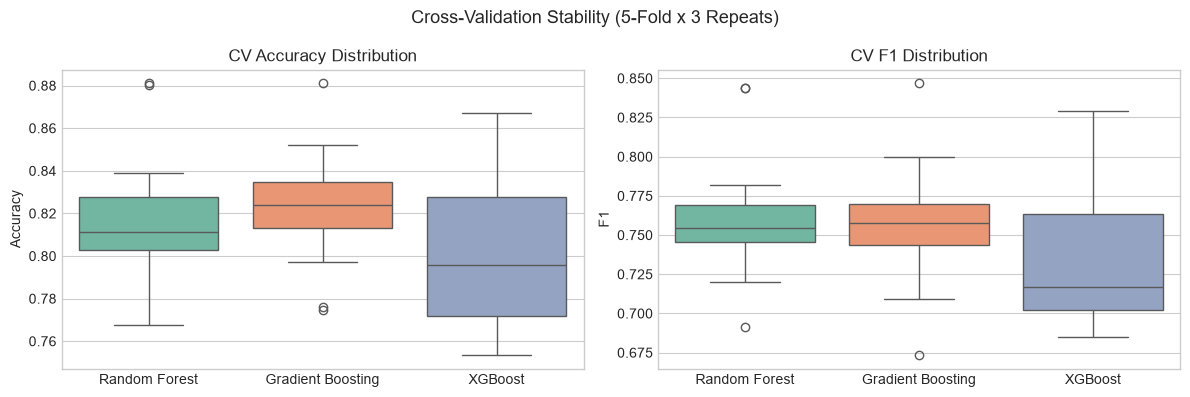

In [12]:
# RepeatedStratifiedKFold gives multiple score estimates on the training set
# This is more reliable than a single train-test split, especially with ~179 test rows
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
cv_results = {}
cv_plot_data = []

for name, pipe in pipelines.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring=["accuracy", "f1"], n_jobs=-1)
    # Summarise mean and std across all 15 folds (5 splits x 3 repeats)
    cv_results[name] = {
        "Accuracy Mean": round(scores["test_accuracy"].mean(), 4),
        "Accuracy Std": round(scores["test_accuracy"].std(), 4),
        "F1 Mean": round(scores["test_f1"].mean(), 4),
        "F1 Std": round(scores["test_f1"].std(), 4)
    }
    # Collect individual fold scores for the boxplot
    for acc, f1 in zip(scores["test_accuracy"], scores["test_f1"]):
        cv_plot_data.append({"Model": name, "Accuracy": acc, "F1": f1})

display(pd.DataFrame(cv_results).T)

# Boxplot shows the spread of scores, not just the average
# A wide box means the model is sensitive to how the data is split
cv_plot_df = pd.DataFrame(cv_plot_data)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=cv_plot_df, x="Model", y="Accuracy", palette="Set2", ax=axes[0])
axes[0].set_title("CV Accuracy Distribution")
axes[0].set_xlabel("")

sns.boxplot(data=cv_plot_df, x="Model", y="F1", palette="Set2", ax=axes[1])
axes[1].set_title("CV F1 Distribution")
axes[1].set_xlabel("")

plt.suptitle("Cross-Validation Stability (5-Fold x 3 Repeats)", fontsize=13)
plt.tight_layout()
plt.show()

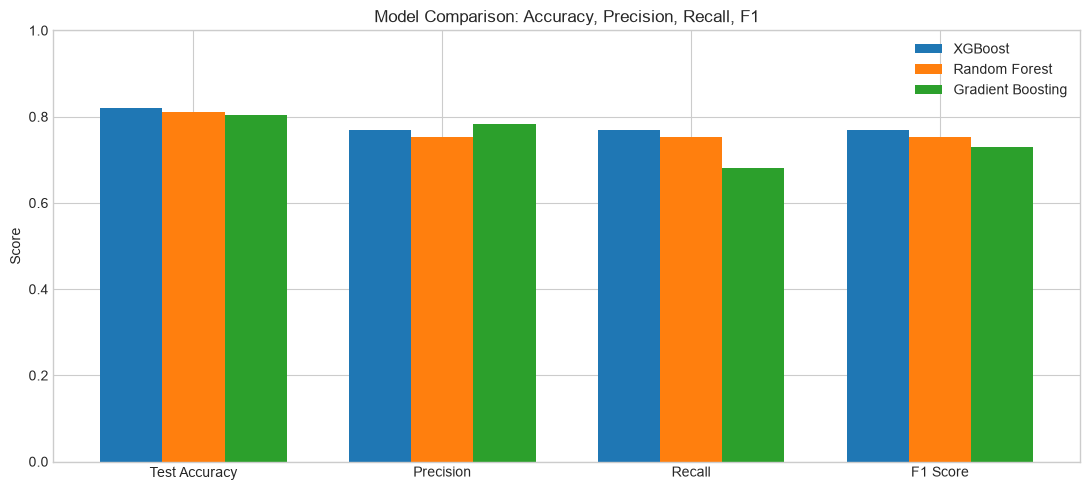

In [13]:
metrics = ["Test Accuracy", "Precision", "Recall", "F1 Score"]
x = np.arange(len(metrics))
width = 0.25  # width of each bar, adjusted so three bars fit side by side

fig, ax = plt.subplots(figsize=(11, 5))

# Plot one group of bars per model, offset slightly along the x-axis
for i, (_, row) in enumerate(results_df.iterrows()):
    ax.bar(x + i * width, [row[m] for m in metrics], width, label=row["Model"])

ax.set_xticks(x + width)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Model Comparison: Accuracy, Precision, Recall, F1")
ax.legend()
plt.tight_layout()
plt.show()

### Step 8: Feature Importance

There are two ways to measure how much each feature contributes to a model's predictions.

**Impurity-based importance** (built into tree models): measures how much each feature reduces impurity (e.g. Gini) across all splits in all trees. It is fast but has two known biases: it tends to overrate continuous features and high-cardinality features simply because they offer more possible split points.

**Permutation importance**: measures how much the model's score drops when the values of one feature are randomly shuffled, breaking its relationship with the target. It is more reliable but slower. One caveat: when two features are correlated, shuffling one may not hurt performance much because the model can still rely on the other, causing both to appear less important than they actually are.

We compute both and compare them to get a more complete picture.

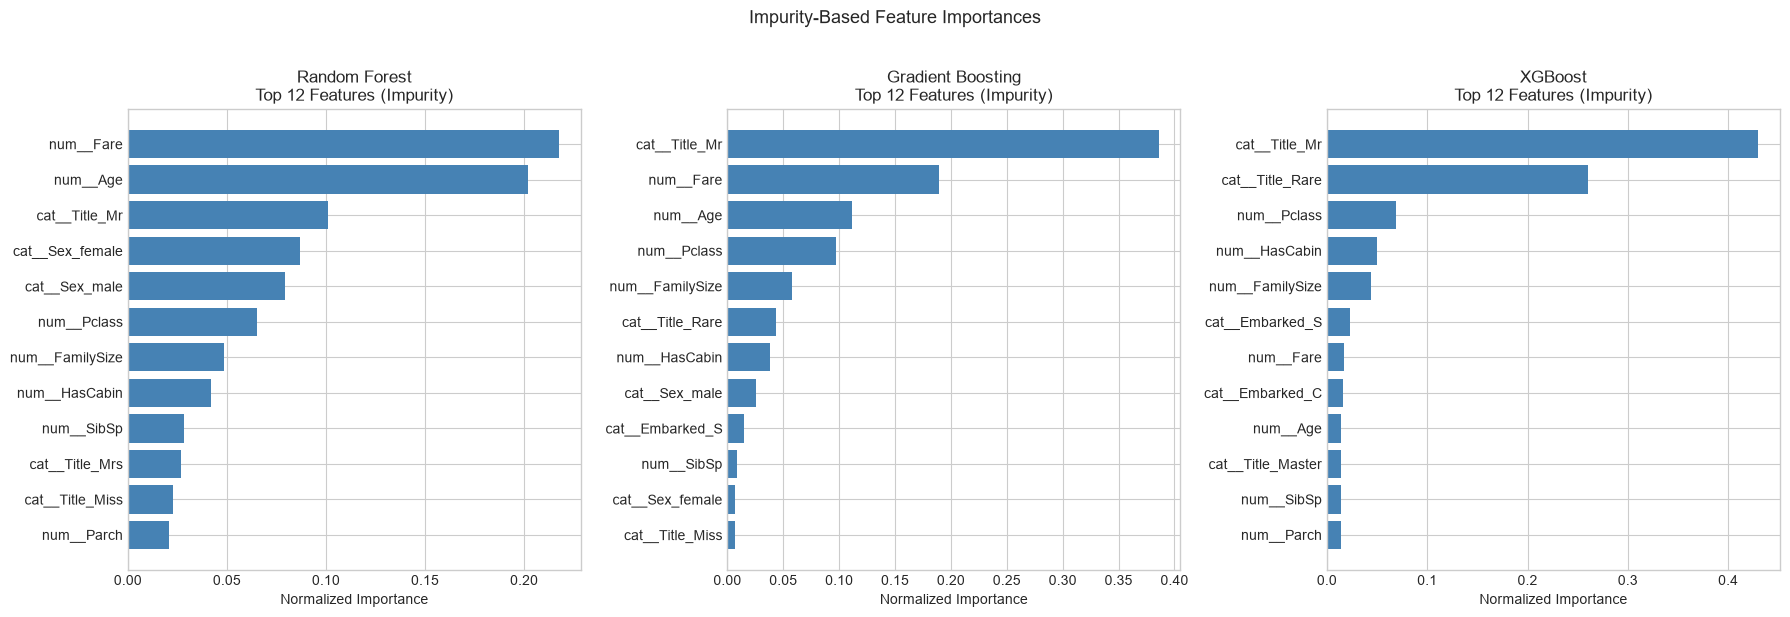

In [14]:
# Extract feature names from the fitted preprocessor
feature_names = preprocessor.get_feature_names_out()

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

impurity_importances = {}

for ax, (name, pipe) in zip(axes, pipelines.items()):
    model = pipe.named_steps["model"]
    importances = model.feature_importances_
    importances_norm = importances / importances.sum()

    # Store for ranking table later
    impurity_importances[name] = pd.Series(importances_norm, index=feature_names)

    top_idx = np.argsort(importances_norm)[-12:]
    ax.barh(feature_names[top_idx], importances_norm[top_idx], color="steelblue")
    ax.set_title(f"{name}\nTop 12 Features (Impurity)")
    ax.set_xlabel("Normalized Importance")

plt.suptitle("Impurity-Based Feature Importances", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

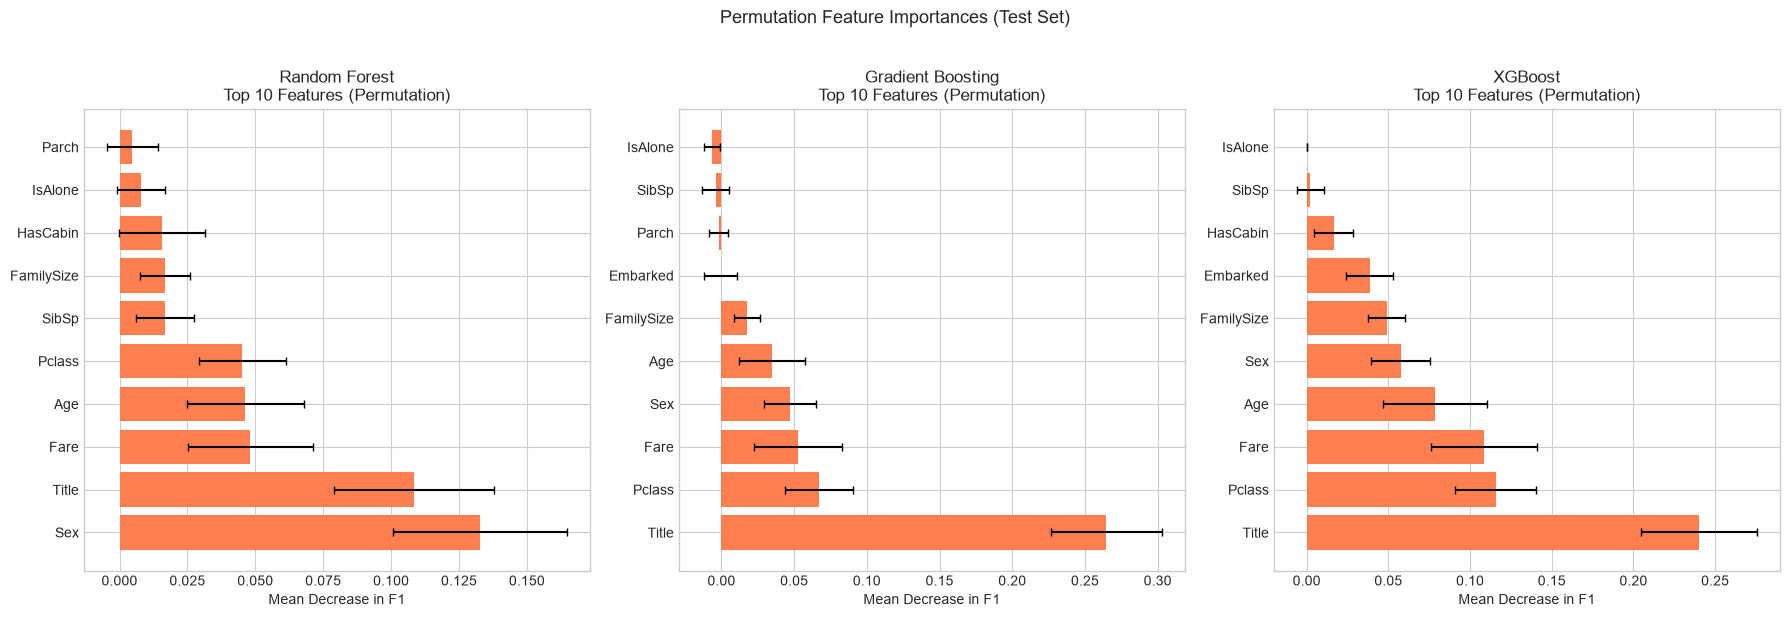

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (name, pipe) in zip(axes, pipelines.items()):
    result = permutation_importance(
        pipe, X_test, y_test,
        scoring="f1",
        n_repeats=30,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    # Use raw column names since we pass the full pipeline
    perm_means = pd.Series(result.importances_mean, index=X_test.columns)
    perm_stds = pd.Series(result.importances_std, index=X_test.columns)

    top_features = perm_means.nlargest(10)
    top_stds = perm_stds[top_features.index]

    ax.barh(top_features.index, top_features.values,
            xerr=top_stds.values, color="coral", ecolor="black", capsize=3)
    ax.set_title(f"{name}\nTop 10 Features (Permutation)")
    ax.set_xlabel("Mean Decrease in F1")

plt.suptitle("Permutation Feature Importances (Test Set)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [16]:
# Rank each feature by impurity importance per model (rank 1 = most important)
rank_df = pd.DataFrame({
    name: imp.rank(ascending=False).astype(int)
    for name, imp in impurity_importances.items()
})

# Show only features that appear in the top 15 of any model
top_mask = (rank_df <= 15).any(axis=1)
display(rank_df[top_mask].sort_values("Random Forest"))

,Random Forest,Gradient Boosting,XGBoost
num__Fare,1,2,7
num__Age,2,3,9
cat__Title_Mr,3,1,1
cat__Sex_female,4,11,15
cat__Sex_male,5,8,17
num__Pclass,6,4,3
num__FamilySize,7,5,5
num__HasCabin,8,7,4
num__SibSp,9,10,11
cat__Title_Mrs,10,13,14



## Analysis

### Performance Summary
The best performing model by F1 score was **XGBoost**, achieving F1 = 0.7681 and test accuracy = 0.8212. The weakest was **Gradient Boosting** with F1 = 0.7287. Random Forest landed in between at F1 = 0.7536. The margin between the three models is small (less than 0.04 F1), so the differences should be interpreted with caution given the small test set size.

### Bagging vs Boosting: What I Observed
Random Forest performed **worse** than XGBoost but **better** than standard GBM by F1. A notable difference is in how GBM handles precision vs recall: it achieved the highest precision (0.7833) but the lowest recall (0.6812), meaning it was conservative in predicting survival and missed more actual survivors than the other two. XGBoost and Random Forest both had balanced precision and recall (equal at 0.7681 and 0.7536 respectively), suggesting they made symmetric trade-offs between false positives and false negatives.

### Overfitting (Train-Test Gap)
**Random Forest** showed the largest train-test accuracy gap at 0.1773, with train accuracy reaching 0.9874 while test accuracy was only 0.8101. This is consistent with the known tendency of Random Forest to grow fully deep, unconstrained trees that memorise training data. XGBoost showed a similar gap (0.1647), while Gradient Boosting had the smallest gap (0.1351), reflecting its use of shallow trees and a learning rate that slows overfitting.

### Training Time
The fastest model was **Gradient Boosting** at 0.35s, followed closely by XGBoost at 0.36s, with Random Forest the slowest at 0.45s. The near-identical times for GBM and XGBoost are partly explained by the small dataset size, which limits XGBoost's speed advantage. Random Forest being slowest here is slightly unexpected given parallel tree building, but 200 deep trees with full feature search can still be costly.

### Top Features: Do the Models Agree?
All three models consistently ranked **Title_Mr** and **Fare** among their top features. There was **moderate** agreement overall. The feature the models disagreed on most was **Title_Rare**: XGBoost ranked it 2nd (impurity) and 1st (permutation), while Random Forest ranked it much lower (18th). This suggests XGBoost found a stronger signal in rare social titles, likely due to its regularization helping it rely on less common but informative splits.

### Impurity vs Permutation Importance: Any Differences?
Impurity importance ranked **Fare** and **Age** at the very top for Random Forest and Gradient Boosting. Permutation importance, however, ranked **Title** and **Sex** as the most influential features across all three models, with Fare dropping to a mid-tier position. This is a textbook example of impurity bias: Fare and Age are continuous features with many possible split points, which inflates their impurity score. Permutation importance, which directly measures the drop in F1 when a feature is shuffled, gives a more realistic picture of their actual predictive value.

### Limitations
The test set contains only 179 rows, so a difference of one or two correct predictions shifts accuracy by almost 1%. The cross-validation results tell a more reliable story: GBM had the highest CV accuracy mean (0.8216) and the lowest standard deviation (0.0261), making it the most stable model. XGBoost, despite topping the single-split metrics, had the lowest CV mean (0.8001) and the highest spread, suggesting its single-split result may have been partially lucky.

### Conclusion
Based on the full picture, **Gradient Boosting** is arguably the most reliable baseline: it has the smallest train-test gap, the best and most stable cross-validation performance, and the highest precision. XGBoost leads on single-split F1 and accuracy but shows less stability across folds. Random Forest is interpretable and fast to tune, but overfits the most at default settings. For a production baseline without tuning, Gradient Boosting is the safest choice. XGBoost is likely to pull ahead once hyperparameter tuning is applied in the next task.
```